# AnÃ¡lisis Comparativo: Datos Originales vs RedistribuciÃ³n

Compara las mÃ©tricas semanales reales del hospital contra los escenarios simulados de redistribuciÃ³n.

**Prerequisitos:**
- `python src/metricas_originales.py` â†’ genera `data/resultados_baseline.csv`
- `python src/experimento.py` â†’ genera `data/resultados_experimento.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

ROOT       = Path('../..')
DATA_DIR   = ROOT / 'data'
OUTPUT_DIR = ROOT / 'output' / 'analisis_comparativo'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PALETTE = {
    'baseline' : '#1565C0',
    'sim'      : '#D32F2F',
    'urg'      : '#E53935',
    'elec'     : '#1E88E5',
    'neutral'  : '#546E7A',
}

def save(name: str):
    path = OUTPUT_DIR / f'{name}.png'
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Guardado: {path}')


In [2]:
# ── Non-pandemic cutoff parameter ──────────────────────────────────────────────────────
# Change CUTOFF to update all non-pandemic means across every chart.
CUTOFF    = '2022-01-01'   # non-pandemic reference date (inclusive)

COLOR_NP  = '#1D9E75'      # teal-green — color for the non-pandemic mean line

In [3]:
# â”€â”€ Carga de datos â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
bl = pd.read_csv(DATA_DIR / 'resultados_baseline.csv', parse_dates=['weekStart'])
bl = bl.sort_values('weekStart').reset_index(drop=True)

sim_path = DATA_DIR / 'resultados_experimento.csv'
sim = pd.read_csv(sim_path) if sim_path.exists() else None

print(f'Baseline: {len(bl)} semanas  ({bl["weekStart"].min().date()} â€“ {bl["weekStart"].max().date()})')
if sim is not None:
    print(f'Experimento: {len(sim):,} filas  |  {sim["iteracion"].nunique()} ventanas')
bl.head()

# Non-pandemic filtered dataset (recalculated whenever CUTOFF changes)
bl_np = bl[bl['weekStart'] >= CUTOFF].copy()
print(f'Non-pandemic (>= {CUTOFF}): {len(bl_np)} weeks')

Baseline: 209 semanas  (2019-12-30 â€“ 2023-12-25)
Experimento: 3,690 filas  |  205 ventanas
Non-pandemic (>= 2022-01-01): 104 weeks


## 1. Throughput semanal â€” serie temporal

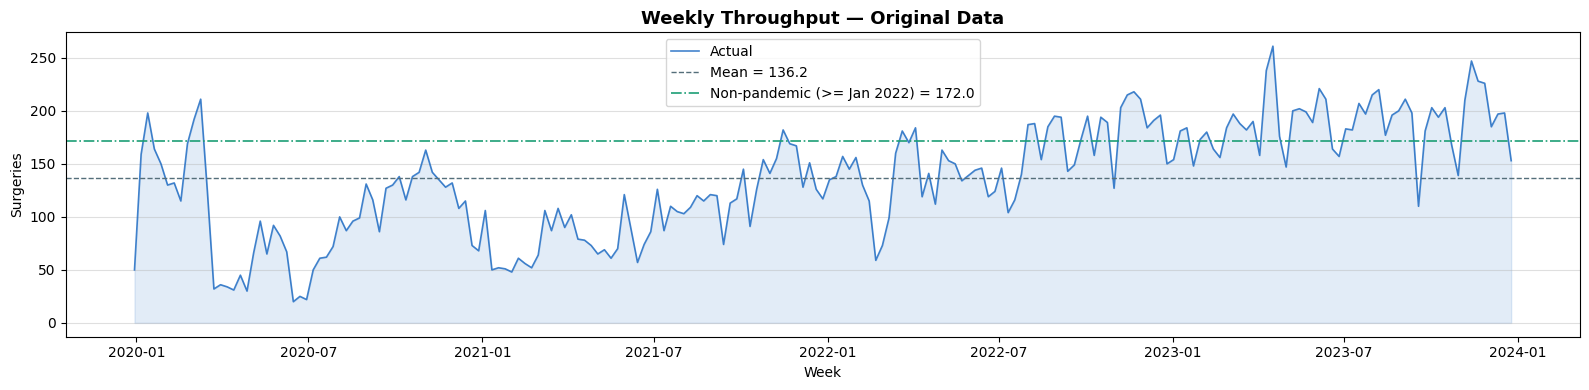

Guardado: ..\..\output\analisis_comparativo\cmp_throughput_serie.png


In [4]:
fig, ax = plt.subplots(figsize=(16, 4))

ax.plot(bl['weekStart'], bl['totalSurgeries'],
        color=PALETTE['baseline'], linewidth=1.2, alpha=0.8, label='Actual')
ax.fill_between(bl['weekStart'], bl['totalSurgeries'],
                alpha=0.12, color=PALETTE['baseline'])

mean_tp = bl['totalSurgeries'].mean()
ax.axhline(mean_tp, color=PALETTE['neutral'], linestyle='--', linewidth=1,
           label=f'Mean = {mean_tp:.1f}')

mean_tp_np = bl_np['totalSurgeries'].mean()
ax.axhline(mean_tp_np, color=COLOR_NP, linestyle='-.', linewidth=1.2,
           label=f'Non-pandemic (>= {pd.Timestamp(CUTOFF).strftime("%b %Y")}) = {mean_tp_np:.1f}')

ax.set_title('Weekly Throughput — Original Data', fontsize=13, fontweight='bold')
ax.set_xlabel('Week'); ax.set_ylabel('Surgeries')
ax.legend()
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
save('cmp_throughput_serie')

## 2. Lead time semanal â€” serie temporal

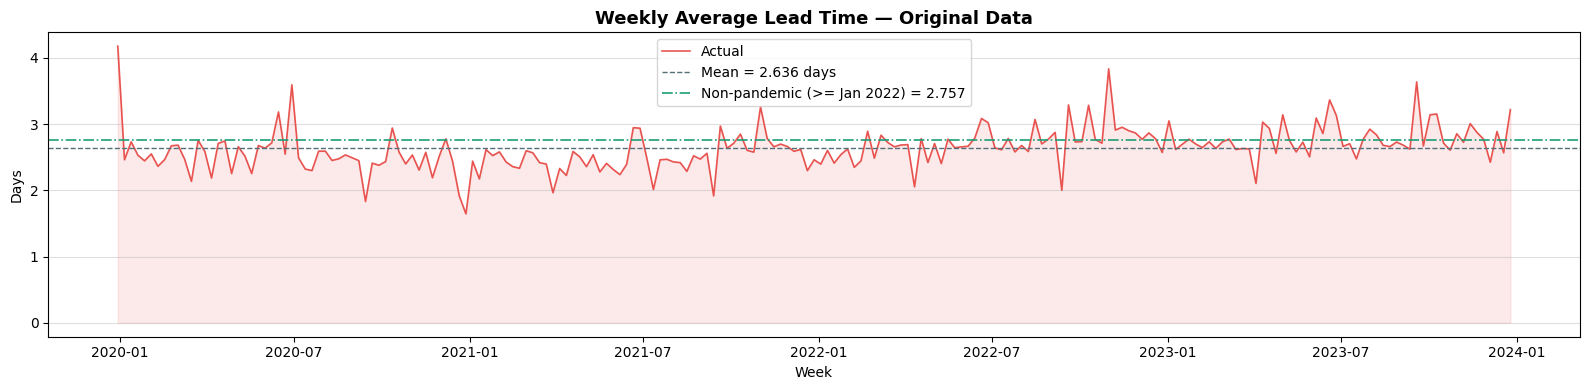

Guardado: ..\..\output\analisis_comparativo\cmp_leadtime_serie.png


In [5]:
fig, ax = plt.subplots(figsize=(16, 4))

ax.plot(bl['weekStart'], bl['avgLeadTimeDays'],
        color=PALETTE['urg'], linewidth=1.2, alpha=0.85, label='Actual')
ax.fill_between(bl['weekStart'], bl['avgLeadTimeDays'],
                alpha=0.1, color=PALETTE['urg'])

mean_lt = bl['avgLeadTimeDays'].mean()
ax.axhline(mean_lt, color=PALETTE['neutral'], linestyle='--', linewidth=1,
           label=f'Mean = {mean_lt:.3f} days')

mean_lt_np = bl_np['avgLeadTimeDays'].mean()
ax.axhline(mean_lt_np, color=COLOR_NP, linestyle='-.', linewidth=1.2,
           label=f'Non-pandemic (>= {pd.Timestamp(CUTOFF).strftime("%b %Y")}) = {mean_lt_np:.3f}')

ax.set_title('Weekly Average Lead Time — Original Data', fontsize=13, fontweight='bold')
ax.set_xlabel('Week'); ax.set_ylabel('Days')
ax.legend()
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
save('cmp_leadtime_serie')

## 3. UtilizaciÃ³n semanal â€” serie temporal (Urg / Elec / Global)

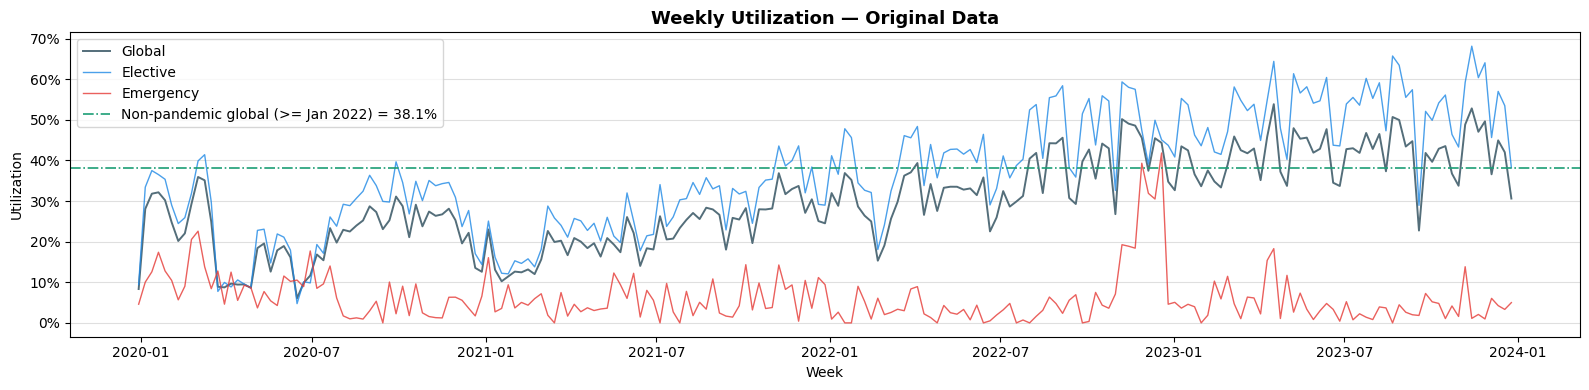

Guardado: ..\..\output\analisis_comparativo\cmp_utilizacion_serie.png


In [6]:
fig, ax = plt.subplots(figsize=(16, 4))

ax.plot(bl['weekStart'], bl['utilGlobal_pct'], color=PALETTE['neutral'],
        linewidth=1.4, label='Global')
ax.plot(bl['weekStart'], bl['utilElec_pct'], color=PALETTE['elec'],
        linewidth=1, alpha=0.8, label='Elective')
ax.plot(bl['weekStart'], bl['utilUrg_pct'], color=PALETTE['urg'],
        linewidth=1, alpha=0.8, label='Emergency')

util_glob_np = bl_np['utilGlobal_pct'].mean()
ax.axhline(util_glob_np, color=COLOR_NP, linestyle='-.', linewidth=1.2,
           label=f'Non-pandemic global (>= {pd.Timestamp(CUTOFF).strftime("%b %Y")}) = {util_glob_np:.1f}%')
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_title('Weekly Utilization — Original Data', fontsize=13, fontweight='bold')
ax.set_xlabel('Week'); ax.set_ylabel('Utilization')
ax.legend()
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
save('cmp_utilizacion_serie')

## 4. DistribuciÃ³n de mÃ©tricas originales

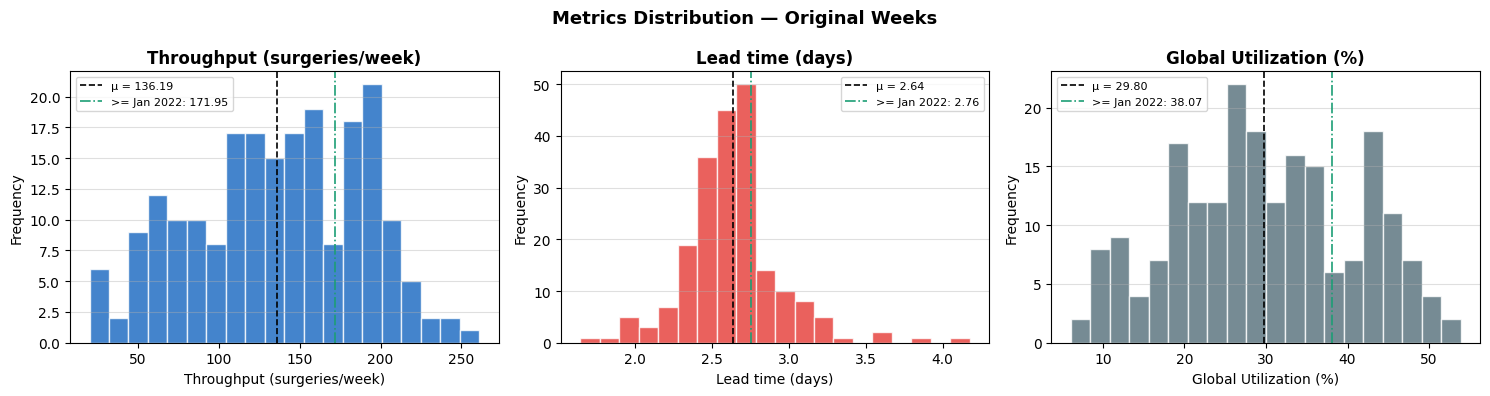

Guardado: ..\..\output\analisis_comparativo\cmp_distribucion_baseline.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ('totalSurgeries',  'Throughput (surgeries/week)', PALETTE['baseline']),
    ('avgLeadTimeDays', 'Lead time (days)',             PALETTE['urg']),
    ('utilGlobal_pct',  'Global Utilization (%)',       PALETTE['neutral']),
]

for ax, (col, label, color) in zip(axes, metrics):
    data = bl[col].dropna()
    ax.hist(data, bins=20, color=color, alpha=0.8, edgecolor='white')
    ax.axvline(data.mean(), color='black', linestyle='--', linewidth=1.2,
               label=f'μ = {data.mean():.2f}')
    data_np = bl_np[col].dropna()
    ax.axvline(data_np.mean(), color=COLOR_NP, linestyle='-.', linewidth=1.2,
               label=f'>= {pd.Timestamp(CUTOFF).strftime("%b %Y")}: {data_np.mean():.2f}')
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel(label); ax.set_ylabel('Frequency')
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.4)

fig.suptitle('Metrics Distribution — Original Weeks', fontsize=13, fontweight='bold')
plt.tight_layout()
save('cmp_distribucion_baseline')

## 5. Urgencias vs Electivas â€” composiciÃ³n semanal

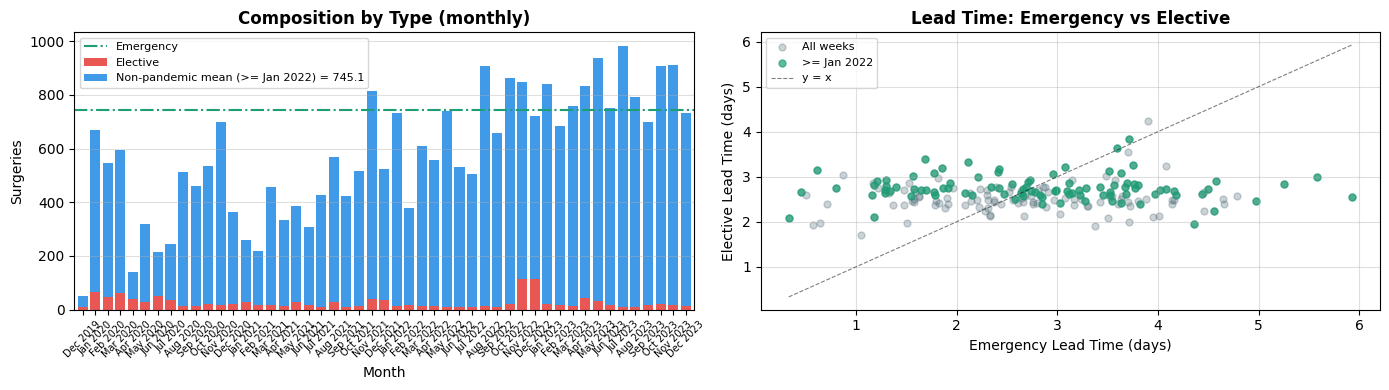

Guardado: ..\..\output\analisis_comparativo\cmp_composicion_leadtime.png


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Stacked bar: composición por mes
ax = axes[0]
sample = (bl[['weekStart', 'urgSurgeries', 'elecSurgeries']]
          .set_index('weekStart')
          .resample('MS').sum())
sample.index = sample.index.strftime('%b %Y')
sample.plot(kind='bar', stacked=True, ax=ax,
            color=[PALETTE['urg'], PALETTE['elec']], alpha=0.85, width=0.8)
ax.set_title('Composition by Type (monthly)', fontweight='bold')
ax.set_xlabel('Month'); ax.set_ylabel('Surgeries')
ax.tick_params(axis='x', rotation=45, labelsize=7)
ax.grid(axis='y', alpha=0.4)

# Media mensual del período no-pandemia (suma semanal → mensual)
np_mean_total = (bl_np[['weekStart', 'urgSurgeries', 'elecSurgeries']]
                 .set_index('weekStart')
                 .resample('MS').sum()
                 .sum(axis=1).mean())
ax.axhline(np_mean_total, color=COLOR_NP, linestyle='-.', linewidth=1.5,
           label=f'Non-pandemic mean (>= {pd.Timestamp(CUTOFF).strftime("%b %Y")}) = {np_mean_total:.1f}')
ax.legend(['Emergency', 'Elective',
           f'Non-pandemic mean (>= {pd.Timestamp(CUTOFF).strftime("%b %Y")}) = {np_mean_total:.1f}'],
          fontsize=8)

# Scatter: lead time urg vs elec
ax2 = axes[1]
ax2.scatter(bl['avgLeadTimeUrg'], bl['avgLeadTimeElec'],
            color=PALETTE['neutral'], alpha=0.3, s=25, label='All weeks')
ax2.scatter(bl_np['avgLeadTimeUrg'], bl_np['avgLeadTimeElec'],
            color=COLOR_NP, alpha=0.7, s=25,
            label=f'>= {pd.Timestamp(CUTOFF).strftime("%b %Y")}')
lims = [min(bl[['avgLeadTimeUrg', 'avgLeadTimeElec']].min()),
        max(bl[['avgLeadTimeUrg', 'avgLeadTimeElec']].max())]
ax2.plot(lims, lims, 'k--', linewidth=0.8, alpha=0.5, label='y = x')
ax2.set_title('Lead Time: Emergency vs Elective', fontweight='bold')
ax2.set_xlabel('Emergency Lead Time (days)')
ax2.set_ylabel('Elective Lead Time (days)')
ax2.legend(fontsize=8)
ax2.grid(alpha=0.4)

plt.tight_layout()
save('cmp_composicion_leadtime')

## 6. Throughput top vs bottom semanas

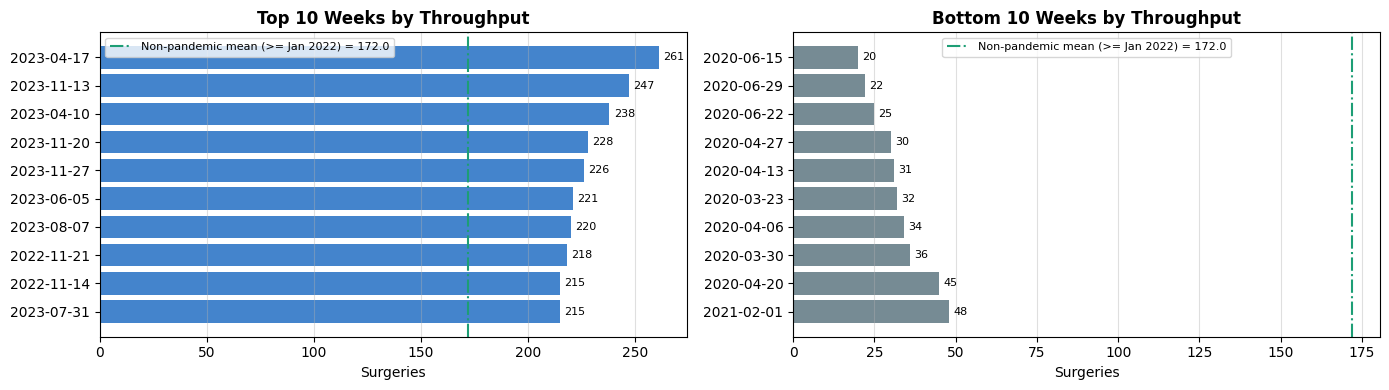

Guardado: ..\..\output\analisis_comparativo\cmp_top_bottom_semanas.png


In [9]:
n = 10
top    = bl.nlargest(n,  'totalSurgeries')[['weekStart', 'totalSurgeries', 'utilGlobal_pct', 'avgLeadTimeDays']]
bottom = bl.nsmallest(n, 'totalSurgeries')[['weekStart', 'totalSurgeries', 'utilGlobal_pct', 'avgLeadTimeDays']]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, data, label, color in [
    (axes[0], top,    f'Top {n} Weeks by Throughput',    PALETTE['baseline']),
    (axes[1], bottom, f'Bottom {n} Weeks by Throughput', PALETTE['neutral']),
]:
    weeks = data['weekStart'].dt.strftime('%Y-%m-%d')
    bars = ax.barh(weeks, data['totalSurgeries'], color=color, alpha=0.8)
    ax.bar_label(bars, fmt='%d', padding=3, fontsize=8)
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel('Surgeries'); ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.4)

np_mean_tp = bl_np['totalSurgeries'].mean()
for ax in axes:
    ax.axvline(np_mean_tp, color=COLOR_NP, linestyle='-.', linewidth=1.5,
               label=f'Non-pandemic mean (>= {pd.Timestamp(CUTOFF).strftime("%b %Y")}) = {np_mean_tp:.1f}')
    ax.legend(fontsize=8)
plt.tight_layout()
save('cmp_top_bottom_semanas')

## 7. ComparaciÃ³n baseline vs simulaciÃ³n (requiere resultados_experimento.csv)

In [10]:
if sim is None:
    print('No se encontrÃ³ resultados_experimento.csv. Ejecuta primero: python src/experimento.py')
else:
    # Agrupamos simulaciÃ³n por combinaciÃ³n heurÃ­stica+estrategia+exclusividad
    sim_grp = (
        sim
        .groupby(['heuristica', 'estrategia', 'salas_exclusivas'])
        [['throughput', 'lead_time', 'util_elec_pct', 'util_global_pct']]
        .mean()
        .round(2)
        .reset_index()
    )
    sim_grp['config'] = (
        sim_grp['heuristica'] + '+' +
        sim_grp['estrategia'] + ' excl=' +
        sim_grp['salas_exclusivas'].astype(str)
    )
    display(sim_grp.sort_values('throughput', ascending=False).head(10))

,heuristica,estrategia,salas_exclusivas,throughput,lead_time,util_elec_pct,util_global_pct,config
15,SPT,S,0,556.68,1.52,99.99,83.23,SPT+S excl=0
12,SPT,A,0,543.46,1.51,93.89,78.53,SPT+A excl=0
16,SPT,S,1,536.78,1.55,91.19,76.41,SPT+S excl=1
13,SPT,A,1,534.99,1.53,90.33,75.74,SPT+A excl=1
17,SPT,S,2,514.31,1.58,92.48,60.82,SPT+S excl=2
14,SPT,A,2,512.71,1.56,91.61,60.30,SPT+A excl=2
3,FIFO,S,0,243.76,1.69,66.95,57.74,FIFO+S excl=0
4,FIFO,S,1,218.29,1.72,60.40,52.65,FIFO+S excl=1
0,FIFO,A,0,202.37,1.68,55.63,49.01,FIFO+A excl=0
5,FIFO,S,2,198.26,1.73,61.72,42.36,FIFO+S excl=2


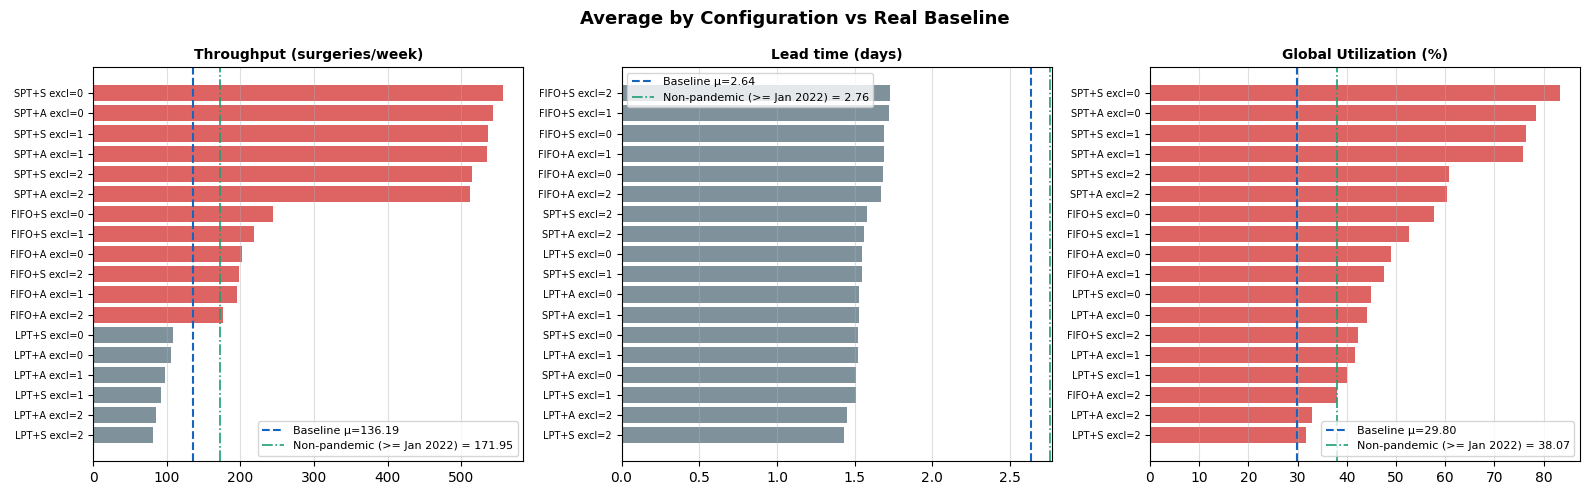

Guardado: ..\..\output\analisis_comparativo\cmp_sim_vs_baseline.png


In [11]:
if sim is not None:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    bl_mean_tp   = bl['totalSurgeries'].mean()
    bl_mean_lt   = bl['avgLeadTimeDays'].mean()
    bl_mean_util = bl['utilGlobal_pct'].mean()

    col_map = {'throughput': 'totalSurgeries', 'lead_time': 'avgLeadTimeDays',
              'util_global_pct': 'utilGlobal_pct'}
    np_means_np = {k: bl_np[v].mean() for k, v in col_map.items()}

    comparisons = [
        (axes[0], sim_grp, 'throughput',      'Throughput (surgeries/week)', bl_mean_tp,   'cmp_tp'),
        (axes[1], sim_grp, 'lead_time',        'Lead time (days)',             bl_mean_lt,   'cmp_lt'),
        (axes[2], sim_grp, 'util_global_pct',  'Global Utilization (%)',       bl_mean_util, 'cmp_util'),
    ]

    for ax, data, col, ylabel, baseline_val, _ in comparisons:
        sorted_data = data.sort_values(col, ascending=False)
        colors = [PALETTE['sim'] if v > baseline_val else PALETTE['neutral']
                  for v in sorted_data[col]]
        ax.barh(sorted_data['config'], sorted_data[col], color=colors, alpha=0.75)
        ax.axvline(baseline_val, color=PALETTE['baseline'], linestyle='--',
                   linewidth=1.5, label=f'Baseline μ={baseline_val:.2f}')
        ax.axvline(np_means_np[col], color=COLOR_NP, linestyle='-.', linewidth=1.2,
                   label=f'Non-pandemic (>= {pd.Timestamp(CUTOFF).strftime("%b %Y")}) = {np_means_np[col]:.2f}')
        ax.set_title(ylabel, fontweight='bold', fontsize=10)
        ax.invert_yaxis()
        ax.legend(fontsize=8)
        ax.tick_params(axis='y', labelsize=7)
        ax.grid(axis='x', alpha=0.4)

    fig.suptitle('Average by Configuration vs Real Baseline', fontsize=13, fontweight='bold')
    plt.tight_layout()
    save('cmp_sim_vs_baseline')

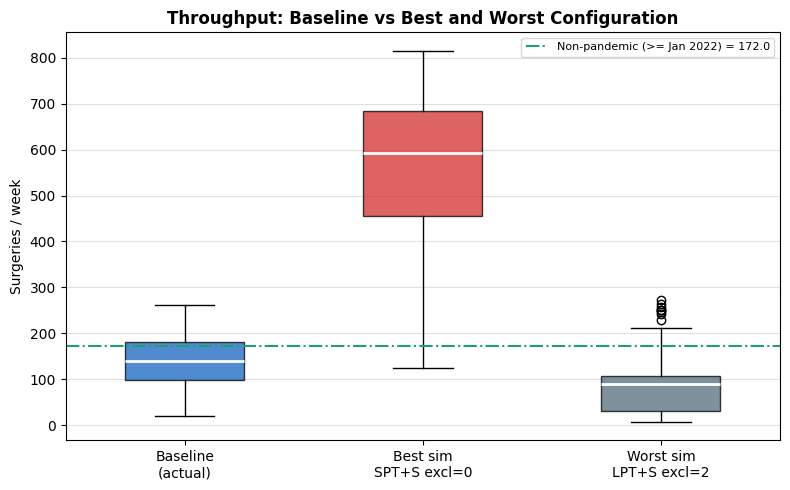

Guardado: ..\..\output\analisis_comparativo\cmp_boxplot_throughput.png


In [12]:
if sim is not None:
    # Box plots: distribuciÃ³n de cada mÃ©trica â€” baseline vs mejor config vs peor config
    best_config  = sim_grp.loc[sim_grp['throughput'].idxmax(),  'config']
    worst_config = sim_grp.loc[sim_grp['throughput'].idxmin(), 'config']

    def _sim_for(config_label: str) -> pd.Series:
        h, rest   = config_label.split('+')
        est, excl = rest.split(' excl=')
        mask = (
            (sim['heuristica']       == h) &
            (sim['estrategia']       == est) &
            (sim['salas_exclusivas'] == int(excl))
        )
        return sim.loc[mask, 'throughput']

    fig, ax = plt.subplots(figsize=(8, 5))

    data_plot = [
        bl['totalSurgeries'].values,
        _sim_for(best_config).values,
        _sim_for(worst_config).values,
    ]
    labels = ['Baseline\n(actual)', f'Best sim\n{best_config}', f'Worst sim\n{worst_config}']
    colors = [PALETTE['baseline'], PALETTE['sim'], PALETTE['neutral']]

    bp = ax.boxplot(data_plot, patch_artist=True, widths=0.5,
                    medianprops=dict(color='white', linewidth=2))
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)

    ax.set_xticklabels(labels)
    ax.set_title('Throughput: Baseline vs Best and Worst Configuration', fontweight='bold')
    ax.set_ylabel('Surgeries / week')
    ax.grid(axis='y', alpha=0.4)
    bl_np_mean_tp = bl_np['totalSurgeries'].mean()
    ax.axhline(bl_np_mean_tp, color=COLOR_NP, linestyle='-.', linewidth=1.5,
               label=f'Non-pandemic (>= {pd.Timestamp(CUTOFF).strftime("%b %Y")}) = {bl_np_mean_tp:.1f}')
    ax.legend(fontsize=8)
    plt.tight_layout()
    save('cmp_boxplot_throughput')

## 8. Tabla resumen

In [13]:
summary = pd.DataFrame({
    'MÃ©trica': [
        'Throughput (surgeries/week)',
        'Lead time promedio (dÃ­as)',
        'UtilizaciÃ³n Urgencias (%)',
        'UtilizaciÃ³n Electivas (%)',
        'UtilizaciÃ³n Global (%)',
    ],
    'Media': [
        bl['totalSurgeries'].mean(),
        bl['avgLeadTimeDays'].mean(),
        bl['utilUrg_pct'].mean(),
        bl['utilElec_pct'].mean(),
        bl['utilGlobal_pct'].mean(),
    ],
    'Mediana': [
        bl['totalSurgeries'].median(),
        bl['avgLeadTimeDays'].median(),
        bl['utilUrg_pct'].median(),
        bl['utilElec_pct'].median(),
        bl['utilGlobal_pct'].median(),
    ],
    'Std': [
        bl['totalSurgeries'].std(),
        bl['avgLeadTimeDays'].std(),
        bl['utilUrg_pct'].std(),
        bl['utilElec_pct'].std(),
        bl['utilGlobal_pct'].std(),
    ],
    'Min': [
        bl['totalSurgeries'].min(),
        bl['avgLeadTimeDays'].min(),
        bl['utilUrg_pct'].min(),
        bl['utilElec_pct'].min(),
        bl['utilGlobal_pct'].min(),
    ],
    'Max': [
        bl['totalSurgeries'].max(),
        bl['avgLeadTimeDays'].max(),
        bl['utilUrg_pct'].max(),
        bl['utilElec_pct'].max(),
        bl['utilGlobal_pct'].max(),
    ],
}).round(3)

display(summary)

,MÃ©trica,Media,Mediana,Std,Min,Max
0,Throughput (surgeries/week),136.187,139.000,52.962,20.000,261.000
1,Lead time promedio (dÃ­as),2.636,2.622,0.319,1.646,4.177
2,UtilizaciÃ³n Urgencias (%),6.087,4.360,6.254,0.000,41.830
3,UtilizaciÃ³n Electivas (%),36.826,35.710,14.397,4.740,68.140
4,UtilizaciÃ³n Global (%),29.800,28.740,11.118,6.060,53.860
